# 03 — Pressure: Stay or Go?

PFF pass-rush micro-analysis. This notebook works directly off `pffScoutingData.csv` and is **independent of Sid's `route_features.parquet`** handoff — it never reads any route-feature parquet. Shared constants are imported from `src/config.py` by their actual names (config is Sid-owned and is not modified here).

In [1]:
# --- imports & reliable project-relative paths ---
import sys
from pathlib import Path

# Locate project root robustly whether cwd is repo root or notebooks/
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / 'src' / 'config.py').exists():
        sys.path.insert(0, str(_p / 'src'))
        _ROOT = _p
        break
else:
    raise SystemExit('Could not locate src/config.py from cwd.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Shared constants imported by their actual names (Sid's config, unmodified).
from config import (
    DATA_DIR, ROOT, TE_RB_POSITIONS, RB_POSITIONS,
    END_EVENTS, NO_THROW_EVENTS, FPS,
)
print('project root:', ROOT)


project root: C:\Users\isaac\CodingProjects\NYUDataBowl


## Input checks

In [2]:
PFF_PATH = DATA_DIR / 'pffScoutingData.csv'
assert PFF_PATH.exists(), f'Missing required input: {PFF_PATH}'
print('PFF scouting data:', PFF_PATH)


PFF scouting data: C:\Users\isaac\CodingProjects\NYUDataBowl\data\pffScoutingData.csv


## Load PFF scouting data

In [3]:
pff = pd.read_csv(PFF_PATH, dtype={'gameId': 'Int64', 'playId': 'Int64', 'nflId': 'Int64'})
print('rows:', len(pff))
print('columns:', list(pff.columns))
pff['pff_role'].value_counts(dropna=False)


rows: 188254
columns: ['gameId', 'playId', 'nflId', 'pff_role', 'pff_positionLinedUp', 'pff_hit', 'pff_hurry', 'pff_sack', 'pff_beatenByDefender', 'pff_hitAllowed', 'pff_hurryAllowed', 'pff_sackAllowed', 'pff_nflIdBlockedPlayer', 'pff_blockType', 'pff_backFieldBlock']


pff_role
Coverage      57765
Pass Block    46057
Pass Route    39513
Pass Rush     36362
Pass           8557
Name: count, dtype: int64

## Pass-rushers per play

Count distinct pass-rushers per `(gameId, playId)`. This is the denominator for any 'pressure vs. extra rusher' analysis. (Earlier inspection conflated the `Pass` role count — one QB per play — with the `Pass Rush` rows; they are not the same.)

In [4]:
pr = pff[pff['pff_role'] == 'Pass Rush'].copy()
print('Pass Rush rows:', len(pr))
print('unique plays with pass rush:', pr.groupby(['gameId','playId']).ngroups)
print('duplicate (gameId,playId,nflId):', int(pr.duplicated(['gameId','playId','nflId']).sum()))
print('missing nflId:', int(pr['nflId'].isna().sum()))

rusher_counts = (pr.drop_duplicates(['gameId','playId','nflId'])
                   .groupby(['gameId','playId'])['nflId'].nunique())
dist = rusher_counts.value_counts().sort_index()
print('--- rusher-count distribution ---')
print(dist.to_string())
print('plays with >=5 rushers:', int((rusher_counts >= 5).sum()))


Pass Rush rows: 36362
unique plays with pass rush: 8556
duplicate (gameId,playId,nflId): 0
missing nflId: 0
--- rusher-count distribution ---
nflId
1       2
2      16
3     420
4    6011
5    1689
6     348
7      69
8       1
plays with >=5 rushers: 2107


## Rusher-count distribution (figure)

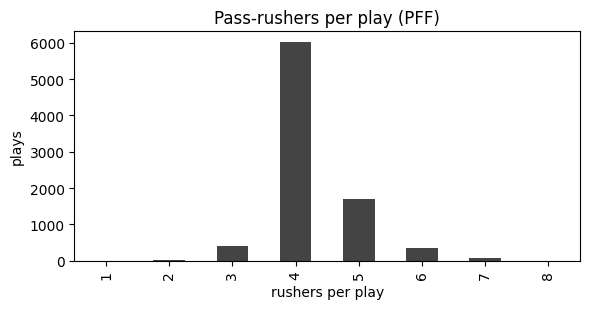

saved: C:\Users\isaac\CodingProjects\NYUDataBowl\figures\rushers_per_play.png


In [5]:
fig, ax = plt.subplots(figsize=(6,3.2))
dist.plot.bar(ax=ax, color='#444')
ax.set_xlabel('rushers per play')
ax.set_ylabel('plays')
ax.set_title('Pass-rushers per play (PFF)')
plt.tight_layout()
out = ROOT / 'figures' / 'rushers_per_play.png'
out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out, dpi=120)
plt.show()
print('saved:', out)


## Pressure production by rusher count

Exploratory only — share of plays with any hit/hurry/sack, split by number of rushers. Not a final result.

In [6]:
prx = pr.groupby(['gameId','playId']).agg(
    n_rushers=('nflId', 'nunique'),
    any_hit=('pff_hit', lambda s: int(s.fillna(0).gt(0).any())),
    any_hurry=('pff_hurry', lambda s: int(s.fillna(0).gt(0).any())),
    any_sack=('pff_sack', lambda s: int(s.fillna(0).gt(0).any())),
).reset_index()
prx['any_pressure'] = prx[['any_hit','any_hurry','any_sack']].max(axis=1)
tbl = prx.groupby('n_rushers')['any_pressure'].agg(['count','mean']).rename(
    columns={'count':'plays','mean':'pressure_rate'})
print(tbl.to_string())


           plays  pressure_rate
n_rushers                      
1              2       0.000000
2             16       0.062500
3            420       0.230952
4           6011       0.346531
5           1689       0.462996
6            348       0.482759
7             69       0.652174
8              1       1.000000


## Chip-benefit: does chipping reduce a rusher's pressure?

Uses only `pffScoutingData.csv`, `players.csv`, `plays.csv` (no tracking, no route-feature parquet). Shared constants imported by their actual names from `src/config` (`TE_RB_POSITIONS`, `RB_POSITIONS`, `N_BOOTSTRAP`, `RANDOM_SEED`).

- **Traditional dropbacks** only (`dropBackType == 'TRADITIONAL'`).
- **Qualifying chipper**: `pff_role == 'Pass Route'`, `pff_blockType == 'CH'`, `officialPosition` in `TE_RB_POSITIONS` (TE/RB/FB).
- **Rusher**: `pff_role == 'Pass Rush'`.
- **Rusher pressure**: `pff_hit == 1` OR `pff_hurry == 1` OR `pff_sack == 1`.
- **Matchup field** linking a chipper to the specific defender: `pff_nflIdBlockedPlayer`.

In [7]:
# --- chip-benefit section: load PFF/players/plays + validated MANY-TO-ONE joins ---
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# shared constants by actual names (idempotent; also set by the setup cell)
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / 'src' / 'config.py').exists():
        sys.path.insert(0, str(_p / 'src')); break
from config import (DATA_DIR, ROOT, TE_RB_POSITIONS, RB_POSITIONS,
                    N_BOOTSTRAP, RANDOM_SEED)

pff = pd.read_csv(DATA_DIR / 'pffScoutingData.csv')
players = pd.read_csv(DATA_DIR / 'players.csv')
plays = pd.read_csv(DATA_DIR / 'plays.csv')

# Join shape: pff is the LEFT (many) side; players and plays are the RIGHT (one)
# sides. These are MANY-TO-ONE joins, not 1:1 — many pff rows share an nflId
# (one per player-play) and many share a (gameId,playId) (one per on-field player).
# What guarantees no row multiplication is that the RIGHT-side keys are unique:
assert players['nflId'].is_unique, 'players.nflId must be unique for many-to-one'
assert plays.duplicated(['gameId','playId']).sum() == 0, 'plays key must be unique'
assert pff.duplicated(['gameId','playId','nflId']).sum() == 0, 'pff key sanity'
print('join shape pff->players: many-to-one | max pff rows per nflId =',
      int(pff.groupby('nflId').size().max()))
print('join shape pff->plays:   many-to-one | max pff rows per play  =',
      int(pff.groupby(['gameId','playId']).size().max()))

n0 = len(pff)
pff = pff.merge(players[['nflId','officialPosition','displayName']], on='nflId', how='left')
pff = pff.merge(plays[['gameId','playId','down','yardsToGo','dropBackType']],
               on=['gameId','playId'], how='left')
# merge-coverage checks (how='left' keeps all pff rows; verify counts + match rates)
assert len(pff) == n0, 'join multiplied rows'
assert pff['officialPosition'].isna().sum() == 0, 'officialPosition missing after players join'
# dropBackType is NaN on 11,616 rows (SCRAMBLE/UNKNOWN/unlabeled plays); the
# TRADITIONAL filter downstream handles it, so it is reported, not asserted away.
assert pff['down'].isna().sum() == 0 and pff['yardsToGo'].isna().sum() == 0, 'down/distance missing'
print('rows after joins:', len(pff), '(unchanged from', n0, ')')
print('players-join match rate:', round(1 - pff['officialPosition'].isna().mean(), 6))
print('plays-join dropBackType NaN rows (SCRAMBLE/UNKNOWN/unlabeled):',
      int(pff['dropBackType'].isna().sum()))

join shape pff->players: many-to-one | max pff rows per nflId = 339
join shape pff->plays:   many-to-one | max pff rows per play  = 22
rows after joins: 188254 (unchanged from 188254 )
players-join match rate: 1.0
plays-join dropBackType NaN rows (SCRAMBLE/UNKNOWN/unlabeled): 11616


### Inspected label values (before selecting columns)

In [8]:
# role distribution + rusher pressure-flag MISSINGNESS audit
# Rule: any observed 1 => pressure; all three observed 0 => no pressure;
# otherwise (>=1 flag NaN and no observed 1) => UNKNOWN (excluded from rates).
print('pff_role:\n', pff['pff_role'].value_counts().to_string())
flags = ['pff_hit','pff_hurry','pff_sack']
pr_all = pff[pff['pff_role'] == 'Pass Rush']
for c in flags:
    print(f'  {c}: NaN={int(pr_all[c].isna().sum())} 1={int((pr_all[c]==1).sum())} 0={int((pr_all[c]==0).sum())}')
n_nan = pr_all[flags].isna().sum(axis=1)
print('  flags-NaN-per-row distribution (0=fully observed .. 3=all NaN):')
print('   ', n_nan.value_counts().sort_index().to_dict())
any1 = (pr_all[flags] == 1).any(axis=1)
all0_obs = (~pr_all[flags].isna()).all(axis=1) & ~any1
partial_unknown = (n_nan.between(1, 2)) & ~any1
all_nan = n_nan.eq(3)
print('  -> pressure (any observed 1):', int(any1.sum()))
print('  -> no pressure (all three observed 0):', int(all0_obs.sum()))
print('  -> UNKNOWN, partial-missing no observed 1:', int(partial_unknown.sum()))
print('  -> UNKNOWN, all flags NaN:', int(all_nan.sum()))
print('  actual missingness: flags are fully observed on every Pass Rush row'
      if int(n_nan.sum()) == 0 else '  actual missingness: some flags are NaN (see above)')

# --- chip-link reconciliation: FULL qualifying sample vs TRADITIONAL dropbacks ---
# Explains the earlier 18-vs-8 discrepancy: 18 unresolved links exist across ALL
# dropback types; restricting to TRADITIONAL (the analysis sample) leaves 8.
_role_by_key = pff.set_index(['gameId','playId','nflId'])['pff_role']

def reconcile_chip_links(df, label):
    chk = df[(df['pff_role']=='Pass Route') & (df['pff_blockType']=='CH')
             & (df['officialPosition'].isin(TE_RB_POSITIONS))].copy()
    blk = chk['pff_nflIdBlockedPlayer']
    n_missing = int(blk.isna().sum())           # missing/invalid target id
    links = chk.loc[blk.notna(), ['gameId','playId']].copy()
    links['blocked_id'] = blk[blk.notna()].astype('int64').values
    tgt_role = links.set_index(['gameId','playId','blocked_id']).index.map(_role_by_key)
    is_pr = (tgt_role == 'Pass Rush')
    is_cov = (tgt_role == 'Coverage')
    not_found = pd.isna(tgt_role)                 # id not present as a pff row on the play
    n_pr, n_cov = int(is_pr.sum()), int(is_cov.sum())
    n_other = int((~is_pr & ~is_cov & ~not_found).sum())
    n_nf = int(not_found.sum())
    uniq_plays = chk[['gameId','playId']].drop_duplicates().shape[0]
    print(f'\n[{label}] chipper rows={len(chk)} | unique plays={uniq_plays}')
    print(f'    chipper positions: {chk["officialPosition"].value_counts().to_dict()}')
    print(f'    matched Pass Rush target: {n_pr}')
    print(f'    matched Coverage target : {n_cov}')
    print(f'    other-role target       : {n_other}')
    print(f'    missing/invalid target  : {n_missing} (NaN id) + {n_nf} (id not on play) '
          f'= {n_missing + n_nf}')
    unresolved_plays = links.loc[~is_pr, ['gameId','playId']].drop_duplicates()
    print(f'    unresolved links (target not a Pass Rush): {int((~is_pr).sum()) + n_missing} '
          f'| affecting {unresolved_plays.shape[0]} unique plays')
    return unresolved_plays

reconcile_chip_links(pff, 'FULL qualifying sample (all dropBackTypes)')
unresolved_trad_plays = reconcile_chip_links(pff[pff['dropBackType']=='TRADITIONAL'],
                                             'TRADITIONAL dropbacks (analysis sample)')
print('\nDISCREPANCY: 18 unresolved chip->Coverage links exist across all dropback'
      ' types; only 8 fall on TRADITIONAL dropbacks. The earlier "18" counted the'
      ' full sample, the "8" counted the TRADITIONAL analysis sample.')

pff_role:
 pff_role
Coverage      57765
Pass Block    46057
Pass Route    39513
Pass Rush     36362
Pass           8557
  pff_hit: NaN=0 1=823 0=35539
  pff_hurry: NaN=0 1=2824 0=33538
  pff_sack: NaN=0 1=585 0=35777
  flags-NaN-per-row distribution (0=fully observed .. 3=all NaN):
    {0: 36362}
  -> pressure (any observed 1): 4232
  -> no pressure (all three observed 0): 32130
  -> UNKNOWN, partial-missing no observed 1: 0
  -> UNKNOWN, all flags NaN: 0
  actual missingness: flags are fully observed on every Pass Rush row

[FULL qualifying sample (all dropBackTypes)] chipper rows=1368 | unique plays=1198
    chipper positions: {'TE': 772, 'RB': 541, 'FB': 55}
    matched Pass Rush target: 1350
    matched Coverage target : 18
    other-role target       : 0
    missing/invalid target  : 0 (NaN id) + 0 (id not on play) = 0
    unresolved links (target not a Pass Rush): 18 | affecting 18 unique plays

[TRADITIONAL dropbacks (analysis sample)] chipper rows=1008 | unique plays=873
    ch

### Per-rusher-play table: chipped flag, pressure, audit

Deduplicate chipper→defender links to one row per `(gameId, playId, blocked_id)`; a rusher is `chipped=1` iff their `nflId` equals a resolved blocked_id on that play (at most one match → no row multiplication).

**Conservative non-chipped classification.** An unlinked rusher is *not* automatically confirmed non-chipped. When a play carries a qualifying chip assignment whose target is unresolved (the blocked id points at a Coverage player / is missing), we cannot rule out that an apparently-unlinked rusher was in fact the chipped defender. For the **primary individual-rusher analysis** we therefore drop every rusher-play on a play that contains any unresolved qualifying chip assignment. On the remaining plays an unmatched rusher is a confirmed non-chipped rusher.

These excluded plays are still retained in the **play-level** chip comparison, where only chip *presence* (any qualifying chipper) and the play's pressure outcome are needed — both known regardless of which defender the chip resolved to.

Unknown pressure outcomes (per the any-1 / all-0 / otherwise-unknown rule) are excluded from rate denominators and audited.

In [9]:
TRAD = pff['dropBackType'] == 'TRADITIONAL'
trad = pff[TRAD].copy()

rushers = trad[trad['pff_role'] == 'Pass Rush'][
    ['gameId','playId','nflId','displayName','officialPosition',
     'pff_hit','pff_hurry','pff_sack','down','yardsToGo']].copy()

chippers = trad[(trad['pff_role']=='Pass Route') & (trad['pff_blockType']=='CH')
              & (trad['officialPosition'].isin(TE_RB_POSITIONS))].copy()

# Classify every qualifying chip link by the role of its blocked target.
# A link is RESOLVED only when the blocked id is a Pass Rush defender on the play.
chippers['blocked_id'] = chippers['pff_nflIdBlockedPlayer']            # may be NaN
_role_by_key = pff.set_index(['gameId','playId','nflId'])['pff_role']
_valid = chippers['blocked_id'].notna()
_bid = chippers.loc[_valid, 'blocked_id'].astype('int64')
_tgt_role = pd.Series(
    _bid.index.map(lambda i: None), index=chippers.index, dtype='object')
_tgt_role.loc[_valid] = (
    pd.MultiIndex.from_arrays([chippers.loc[_valid,'gameId'],
                               chippers.loc[_valid,'playId'], _bid]).map(_role_by_key))
chippers['target_role'] = _tgt_role
chippers['resolved'] = (chippers['target_role'] == 'Pass Rush')

# Plays carrying ANY unresolved qualifying chip assignment (missing id OR target
# not a pass rusher). On these plays an unlinked rusher cannot be confirmed
# non-chipped, so they are excluded from the primary individual-rusher analysis.
unresolved_plays = (chippers.loc[~chippers['resolved'], ['gameId','playId']]
                    .drop_duplicates())
unresolved_plays_set = set(map(tuple, unresolved_plays.to_numpy()))
rushers['play_has_unresolved_chip'] = [
    (g, p) in unresolved_plays_set
    for g, p in zip(rushers['gameId'], rushers['playId'])]

# dedup RESOLVED links only; mark rushers chipped (<=1 match -> no multiplication)
chip_links = (chippers.loc[chippers['resolved'], ['gameId','playId']]
              .assign(blocked_id=chippers.loc[chippers['resolved'],'blocked_id'].astype('int64'))
              [['gameId','playId','blocked_id']].drop_duplicates())
rushers = rushers.merge(chip_links, left_on=['gameId','playId','nflId'],
                       right_on=['gameId','playId','blocked_id'], how='left')
rushers['chipped'] = rushers['blocked_id'].notna().astype(int)

# pressure classification: any observed 1 -> 1; all three observed 0 -> 0;
# otherwise (>=1 flag NaN and no observed 1) -> unknown (NaN, excluded from rates)
flags = ['pff_hit','pff_hurry','pff_sack']
any1 = (rushers[flags] == 1).any(axis=1)
all0_observed = (~rushers[flags].isna()).all(axis=1) & ~any1
rushers['pressure'] = np.nan
rushers.loc[any1, 'pressure'] = 1
rushers.loc[all0_observed, 'pressure'] = 0

n_unknown = int(rushers['pressure'].isna().sum())
n_excluded_rows = int(rushers['play_has_unresolved_chip'].sum())
n_unresolved_links = int((~chippers['resolved']).sum())
print('Pass Rush rows (traditional):', len(rushers))
print('unknown-outcome rusher rows (excluded from rates):', n_unknown)
print('chipped rusher-play rows (resolved links):', int(rushers['chipped'].sum()))
print('unresolved qualifying chip links:', n_unresolved_links,
      '| plays affected:', len(unresolved_plays))
print('rusher-play rows on unresolved-chip plays '
      '(excluded from INDIVIDUAL analysis, kept for PLAY-LEVEL):', n_excluded_rows)

# primary individual-rusher frame: drop rows on unresolved-chip plays
rushers_ind = rushers[~rushers['play_has_unresolved_chip']].copy()
print('rusher-play rows retained for individual analysis:', len(rushers_ind))

# verified chipper -> rusher examples (resolved links only)
ex = chip_links.merge(rushers[['gameId','playId','nflId','displayName','officialPosition','chipped','pressure']],
                  left_on=['gameId','playId','blocked_id'], right_on=['gameId','playId','nflId'],
                  how='inner')
ex.head(6)[['gameId','playId','blocked_id','displayName','officialPosition','chipped','pressure']]

Pass Rush rows (traditional): 27833
unknown-outcome rusher rows (excluded from rates): 0
chipped rusher-play rows (resolved links): 997
unresolved qualifying chip links: 8 | plays affected: 8
rusher-play rows on unresolved-chip plays (excluded from INDIVIDUAL analysis, kept for PLAY-LEVEL): 31
rusher-play rows retained for individual analysis: 27802


,gameId,playId,blocked_id,displayName,officialPosition,chipped,pressure
0,2021090900,349,41915,Shaquil Barrett,OLB,1,0.0
1,2021090900,480,46185,Dorance Armstrong,DE,1,0.0
2,2021090900,2419,53441,Micah Parsons,OLB,1,1.0
3,2021090900,3793,44892,Tarell Basham,DE,1,0.0
4,2021090900,3793,52587,Bradlee Anae,DE,1,0.0
5,2021090900,4189,41915,Shaquil Barrett,OLB,1,0.0


### Within-rusher estimate

Computed on the **primary individual-rusher cohort** (`rushers_ind`): traditional pass-rush rows with a known pressure outcome, **excluding** every rusher-play on a play that carried an unresolved qualifying chip assignment. For each rusher with **≥5 chipped AND ≥5 non-chipped** eligible dropbacks, compute `pressure_rate(chipped) − pressure_rate(non-chipped)` in percentage points. Report the **median** of these within-rusher differences. Bootstrap: 1000 resamples over eligible rushers (with replacement), fixed seed (`RANDOM_SEED`+offset), 95% percentile CI. Passing downs = `down>=3 AND yardsToGo>=7`; the 5/5 gate is applied **within** each subgroup, so the eligible cohort can differ.

In [10]:
def within_rusher(df_elig, seed):
    rows = []
    for nid, g in df_elig.groupby('nflId'):
        ch = g[g['chipped']==1]; nc = g[g['chipped']==0]
        if len(ch) >= 5 and len(nc) >= 5:
            r_ch = ch['pressure'].mean(); r_nc = nc['pressure'].mean()
            rows.append(dict(nflId=nid, displayName=g['displayName'].iloc[0],
                            officialPosition=g['officialPosition'].iloc[0],
                            n_chipped=len(ch), n_nonchipped=len(nc),
                            pressure_chipped=int(ch['pressure'].sum()),
                            pressure_nonchipped=int(nc['pressure'].sum()),
                            rate_chipped=r_ch, rate_nonchipped=r_nc,
                            diff_pp=(r_ch - r_nc)*100))
    det = pd.DataFrame(rows)
    diffs = det['diff_pp'].to_numpy() if len(det) else np.array([])
    n_elig = len(det)
    if n_elig == 0:
        return dict(n_eligible_rushers=0, median=np.nan, ci_low=np.nan, ci_high=np.nan,
                    det=det, n_ch_exp=0, n_nc_exp=0, p_ch_exp=0, p_nc_exp=0)
    rng = np.random.default_rng(seed)
    meds = np.empty(N_BOOTSTRAP)
    for b in range(N_BOOTSTRAP):
        idx = rng.integers(0, n_elig, size=n_elig)
        meds[b] = np.median(diffs[idx])
    ci_low, ci_high = np.percentile(meds, [2.5, 97.5])
    return dict(n_eligible_rushers=n_elig, median=float(np.median(diffs)),
               ci_low=float(ci_low), ci_high=float(ci_high), det=det,
               n_ch_exp=int(det['n_chipped'].sum()), n_nc_exp=int(det['n_nonchipped'].sum()),
               p_ch_exp=int(det['pressure_chipped'].sum()), p_nc_exp=int(det['pressure_nonchipped'].sum()))

# primary individual-rusher cohort: known pressure AND not on an unresolved-chip play
elig_all = rushers_ind[rushers_ind['pressure'].notna()]
passing = (elig_all['down'] >= 3) & (elig_all['yardsToGo'] >= 7)
R_all   = within_rusher(elig_all, RANDOM_SEED)
R_pass  = within_rusher(elig_all[passing], RANDOM_SEED + 1)
R_other = within_rusher(elig_all[~passing], RANDOM_SEED + 2)

print('missing down/distance in traditional rusher rows:',
      int(rushers_ind['down'].isna().sum()), int(rushers_ind['yardsToGo'].isna().sum()))
for name, R in [('all_downs', R_all), ('passing_downs', R_pass), ('other_downs', R_other)]:
    print(f'{name}: n_eligible={R["n_eligible_rushers"]} median={R["median"]:.2f}pp '
          f'CI=[{R["ci_low"]:.2f},{R["ci_high"]:.2f}] '
          f'chipped_exposure={R["n_ch_exp"]} nonchipped_exposure={R["n_nc_exp"]}')

missing down/distance in traditional rusher rows: 0 0
all_downs: n_eligible=77 median=-6.40pp CI=[-6.98,-4.12] chipped_exposure=704 nonchipped_exposure=8214
passing_downs: n_eligible=14 median=-7.42pp CI=[-14.06,4.09] chipped_exposure=95 nonchipped_exposure=330
other_downs: n_eligible=54 median=-4.88pp CI=[-7.11,-1.51] chipped_exposure=398 nonchipped_exposure=5043


### Play-level comparison (any-rusher pressure; game-cluster bootstrap)

One row per traditional play: `has_chip` (any qualifying chipper) vs no chip, and `any_pressure` (any rusher recorded pressure) vs none. This comparison uses the **full** set of traditional plays — plays with an unresolved chip target stay in, because only chip *presence* and the play's pressure *outcome* are needed, and both are known regardless of which defender the chip resolved to. The pooled play-level rate difference is a **descriptive** contrast of pressure on chip vs no-chip plays; it does not establish pressure redistribution or causality. Bootstrap resamples **games** with replacement, preserving every sampled game's plays and multiplicity; draws with no chip or no no-chip plays are unusable. The game-cluster CI is an implementation choice, not a rule from the plan.

In [11]:
# one row per traditional play
play_rows = rushers.groupby(['gameId','playId'], as_index=False).agg(n_rushers=('nflId','nunique'))
pres_by_play = (rushers.groupby(['gameId','playId'])['pressure']
              .agg(lambda s: 1 if (s==1).any() else (0 if s.notna().any() else np.nan))
              .rename('any_pressure').reset_index())
play_rows = play_rows.merge(pres_by_play, on=['gameId','playId'])
chip_key_df = chippers[['gameId','playId']].drop_duplicates().assign(has_chip=1)
play_rows = play_rows.merge(chip_key_df, on=['gameId','playId'], how='left')
play_rows['has_chip'] = play_rows['has_chip'].fillna(0).astype(int)

play_known = play_rows[play_rows['any_pressure'].notna()].copy()
chip = play_known[play_known['has_chip']==1]
nochip = play_known[play_known['has_chip']==0]
rate_chip = chip['any_pressure'].mean(); rate_nochip = nochip['any_pressure'].mean()
play_diff = (rate_chip - rate_nochip) * 100
print(f'chip plays={len(chip)} (pressure={int(chip["any_pressure"].sum())}) '
      f'| nochip plays={len(nochip)} (pressure={int(nochip["any_pressure"].sum())})')
print(f'rate_chip={rate_chip:.4f} rate_nochip={rate_nochip:.4f} diff={play_diff:.2f}pp')

# game-cluster bootstrap (resample games w/ replacement; multiplicity preserved)
pg = play_known.copy()
pg['chip_plays'] = (pg['has_chip']==1).astype(int)
pg['nochip_plays'] = (pg['has_chip']==0).astype(int)
pg['chip_pres'] = ((pg['has_chip']==1) & (pg['any_pressure']==1)).astype(int)
pg['nochip_pres'] = ((pg['has_chip']==0) & (pg['any_pressure']==1)).astype(int)
per_game = pg.groupby('gameId')[['chip_plays','nochip_plays','chip_pres','nochip_pres']].sum().reset_index()
games = per_game['gameId'].to_numpy(); n_games = len(games)
cp = per_game['chip_plays'].to_numpy(); np_ = per_game['nochip_plays'].to_numpy()
cpr = per_game['chip_pres'].to_numpy(); npr = per_game['nochip_pres'].to_numpy()
rng = np.random.default_rng(RANDOM_SEED + 3)
draws = []; unusable = 0
for b in range(N_BOOTSTRAP):
    idx = rng.integers(0, n_games, size=n_games)
    tchip = cp[idx].sum(); tnochip = np_[idx].sum()
    if tchip == 0 or tnochip == 0:
        unusable += 1; continue
    draws.append((cpr[idx].sum()/tchip - npr[idx].sum()/tnochip) * 100)
draws = np.array(draws)
pl_ci_low, pl_ci_high = (np.nanpercentile(draws, [2.5, 97.5]) if len(draws) else (np.nan, np.nan))
print(f'play-level bootstrap: usable={len(draws)} unusable={unusable} '
      f'CI=[{pl_ci_low:.2f},{pl_ci_high:.2f}]')

chip plays=873 (pressure=315) | nochip plays=5669 (pressure=1755)
rate_chip=0.3608 rate_nochip=0.3096 diff=5.12pp
play-level bootstrap: usable=1000 unusable=0 CI=[1.36,9.19]


### Save compact results + audit to `data/isaac/`

In [12]:
def wr_rows(R, population, comparison):
    return [
        dict(comparison=comparison, population=population, metric='chipped_pressure_rate',
             estimate=round(R['p_ch_exp']/R['n_ch_exp'], 6) if R['n_ch_exp'] else np.nan,
             ci_low=np.nan, ci_high=np.nan, unit='proportion',
             num=R['p_ch_exp'], den=R['n_ch_exp'], n_eligible_rushers=R['n_eligible_rushers'],
             n_unusable_draws=np.nan, notes='pooled chipped pressure rate across eligible rushers'),
        dict(comparison=comparison, population=population, metric='nonchipped_pressure_rate',
             estimate=round(R['p_nc_exp']/R['n_nc_exp'], 6) if R['n_nc_exp'] else np.nan,
             ci_low=np.nan, ci_high=np.nan, unit='proportion',
             num=R['p_nc_exp'], den=R['n_nc_exp'], n_eligible_rushers=R['n_eligible_rushers'],
             n_unusable_draws=np.nan, notes='pooled non-chipped pressure rate across eligible rushers'),
        dict(comparison=comparison, population=population, metric='median_within_rusher_diff',
             estimate=round(R['median'], 4), ci_low=round(R['ci_low'], 4), ci_high=round(R['ci_high'], 4),
             unit='percentage_points', num=np.nan, den=np.nan,
             n_eligible_rushers=R['n_eligible_rushers'], n_unusable_draws=0,
             notes='median of per-rusher (chipped - nonchipped) pressure-rate diffs'),
    ]

results = pd.DataFrame(
    wr_rows(R_all, 'all_downs', 'within_rusher')
    + wr_rows(R_pass, 'passing_downs', 'within_rusher')
    + wr_rows(R_other, 'other_downs', 'within_rusher')
    + [dict(comparison='play_level', population='all_downs', metric='chip_pressure_rate',
            estimate=round(rate_chip, 6), ci_low=np.nan, ci_high=np.nan, unit='proportion',
            num=int(chip['any_pressure'].sum()), den=len(chip), n_eligible_rushers=np.nan,
            n_unusable_draws=np.nan, notes='play-level any-rusher pressure rate on chipped plays'),
       dict(comparison='play_level', population='all_downs', metric='nochip_pressure_rate',
            estimate=round(rate_nochip, 6), ci_low=np.nan, ci_high=np.nan, unit='proportion',
            num=int(nochip['any_pressure'].sum()), den=len(nochip), n_eligible_rushers=np.nan,
            n_unusable_draws=np.nan, notes='play-level any-rusher pressure rate on non-chipped plays'),
       dict(comparison='play_level', population='all_downs', metric='pooled_play_level_diff',
            estimate=round(play_diff, 4), ci_low=round(float(pl_ci_low), 4), ci_high=round(float(pl_ci_high), 4),
            unit='percentage_points', num=np.nan, den=np.nan, n_eligible_rushers=np.nan,
            n_unusable_draws=unusable, notes='pooled (chip - nochip) play-level diff; game-cluster bootstrap')]
)

# within-rusher detail (eligible rushers per population; cohorts can differ)
det_frames = []
for pop, R in [('all_downs', R_all), ('passing_downs', R_pass), ('other_downs', R_other)]:
    d = R['det'].copy(); d['population'] = pop; det_frames.append(d)
detail = pd.concat(det_frames, ignore_index=True)

audit = pd.DataFrame([
    dict(item='pff_rows_total', value=len(pff)),
    dict(item='pass_rush_rows_traditional', value=len(rushers)),
    dict(item='traditional_dropback_plays', value=len(play_known)),
    dict(item='plays_with_qualifying_chip', value=len(chip_key_df)),
    dict(item='plays_without_qualifying_chip', value=int((play_known['has_chip']==0).sum())),
    dict(item='qualifying_chipper_rows', value=len(chippers)),
    dict(item='chipped_rusher_play_rows', value=int(rushers['chipped'].sum())),
    dict(item='unknown_outcome_rusher_rows', value=n_unknown),
    dict(item='unresolved_chip_links_nonrusher', value=n_unresolved_links),
    dict(item='plays_with_unresolved_chip', value=int(len(unresolved_plays))),
    dict(item='rusher_rows_excluded_unresolved_play', value=n_excluded_rows),
    dict(item='rusher_rows_individual_analysis', value=len(rushers_ind)),
    dict(item='passing_downs_rusher_rows', value=int(passing.sum())),
    dict(item='other_downs_rusher_rows', value=int((~passing).sum())),
    dict(item='down_missing_traditional', value=int(rushers_ind['down'].isna().sum())),
    dict(item='yardstogo_missing_traditional', value=int(rushers_ind['yardsToGo'].isna().sum())),
    dict(item='n_games_playlevel', value=int(n_games)),
    dict(item='n_bootstrap', value=N_BOOTSTRAP),
    dict(item='random_seed', value=RANDOM_SEED),
])

OUT = ROOT / 'data' / 'isaac'
OUT.mkdir(parents=True, exist_ok=True)
results.to_csv(OUT / 'chip_benefit_results.csv', index=False)
detail.to_csv(OUT / 'chip_benefit_within_rusher.csv', index=False)
audit.to_csv(OUT / 'chip_benefit_audit.csv', index=False)
print('saved 3 tables to', OUT)
results

saved 3 tables to C:\Users\isaac\CodingProjects\NYUDataBowl\data\isaac


,comparison,population,metric,estimate,ci_low,ci_high,unit,num,den,n_eligible_rushers,n_unusable_draws,notes
0,within_rusher,all_downs,chipped_pressure_rate,0.075284,NaN,NaN,proportion,53.0,704.0,77.0,NaN,pooled chipped pressure rate across eligible r...
1,within_rusher,all_downs,nonchipped_pressure_rate,0.114439,NaN,NaN,proportion,940.0,8214.0,77.0,NaN,pooled non-chipped pressure rate across eligib...
2,within_rusher,all_downs,median_within_rusher_diff,-6.402000,-6.9819,-4.1237,percentage_points,NaN,NaN,77.0,0.0,median of per-rusher (chipped - nonchipped) pr...
3,within_rusher,passing_downs,chipped_pressure_rate,0.115789,NaN,NaN,proportion,11.0,95.0,14.0,NaN,pooled chipped pressure rate across eligible r...
4,within_rusher,passing_downs,nonchipped_pressure_rate,0.145455,NaN,NaN,proportion,48.0,330.0,14.0,NaN,pooled non-chipped pressure rate across eligib...
5,within_rusher,passing_downs,median_within_rusher_diff,-7.417600,-14.0642,4.0860,percentage_points,NaN,NaN,14.0,0.0,median of per-rusher (chipped - nonchipped) pr...
6,within_rusher,other_downs,chipped_pressure_rate,0.070352,NaN,NaN,proportion,28.0,398.0,54.0,NaN,pooled chipped pressure rate across eligible r...
7,within_rusher,other_downs,nonchipped_pressure_rate,0.109260,NaN,NaN,proportion,551.0,5043.0,54.0,NaN,pooled non-chipped pressure rate across eligib...
8,within_rusher,other_downs,median_within_rusher_diff,-4.881000,-7.1069,-1.5079,percentage_points,NaN,NaN,54.0,0.0,median of per-rusher (chipped - nonchipped) pr...
9,play_level,all_downs,chip_pressure_rate,0.360825,NaN,NaN,proportion,315.0,873.0,NaN,NaN,play-level any-rusher pressure rate on chipped...


In [13]:
# --- sanity checks ---
print('duplicate rusher-play keys:', int(rushers.duplicated(['gameId','playId','nflId']).sum()))
prop_ok = ((results['estimate'].dropna().between(0,1)) | (results['unit']=='percentage_points')).all()
print('proportions in [0,1] (or pp):', bool(prop_ok))
print('within-rusher median sign (all_downs):', int(np.sign(R_all['median'])))
print('play-level diff sign:', int(np.sign(play_diff)))
print('n_eligible all/pass/other:', R_all['n_eligible_rushers'], R_pass['n_eligible_rushers'], R_other['n_eligible_rushers'])
print('play-level chip+nochip == total known plays:', len(chip)+len(nochip) == len(play_known))

duplicate rusher-play keys: 0
proportions in [0,1] (or pp): True
within-rusher median sign (all_downs): -1
play-level diff sign: 1
n_eligible all/pass/other: 77 14 54
play-level chip+nochip == total known plays: True


### What a coach can — and cannot — infer

> Numeric estimates below are filled in from the regenerated `data/isaac/chip_benefit_results.csv` after this notebook is rerun. The cohort now **excludes** rusher-plays on plays that carried an unresolved qualifying chip assignment.

**Can infer (descriptive, this dataset):**
- At the **individual rusher** level, being chipped is associated with **lower** pressure on that rusher (see `median_within_rusher_diff` for `all_downs`, with its 95% CI, over the eligible rushers reported in the table). Non-passing (`other_downs`) and passing-down subgroups are reported separately; the 5/5 gate is applied within each subgroup so the eligible cohort differs across them.
- At the **play** level, plays **with** a chip show **higher** any-rusher pressure (`pooled_play_level_diff`, with its game-cluster-bootstrap CI).
- Taken together: **lower pressure on matched chipped rushers coexists with higher overall pressure on chip plays; these descriptive comparisons do not establish pressure redistribution or causality.**

**Cannot infer:**
- **Causation.** A negative chip-minus-no-chip pressure rate means lower *observed* pressure with a chip, not that the chip *caused* the drop. Chipping is not assigned at random; plays with a chip differ in scheme, personnel, and down/distance.
- That the within-rusher median and the pooled play-level difference measure the same thing — they do not (one is a median of per-rusher diffs over a 5/5-gated cohort that excludes unresolved-chip plays; the other is a pooled play-level rate difference over all traditional plays). Their opposite signs are a descriptive contrast, not evidence that pressure moves from one defender to another.
- A matched comparison across down subgroups: the 5/5 gate is applied within each subgroup, so the eligible rusher cohort differs.
- Generalization beyond this sample without the source plan/event-overview documents, which remain unverified dependencies (not read here).

## Next steps / open questions

- Snap and endpoint event ordering when multiple autoevents fire needs confirming with Sid (`SNAP_EVENTS` / `END_EVENTS` in config) before timing pressure windows.
- Does `NO_THROW_EVENTS` (qb_sack / qb_strip_sack / run) correctly mark no-throw plays for the stay-or-go split?
- This notebook is intentionally independent of `route_features.parquet`; pressure may later be joined to route outcomes once Sid's handoff lands.

> Event-handling questions go to Sid. Do not assume every autoevent is interchangeable without checking endpoint precedence.

**Chip-benefit follow-ups:**
- Confirm with Sid the semantics of `pff_nflIdBlockedPlayer` for chip blocks. Reconciliation: in the FULL qualifying sample 1,350 of 1,368 CH links map to a Pass Rush defender and 18 point at a Coverage player (unresolved); restricting to TRADITIONAL dropbacks leaves 1,000 of 1,008 resolved and 8 unresolved. The earlier ‘18 vs 8’ gap was simply full-sample vs TRADITIONAL-only counting.
- Unresolved links are never forced onto a rusher. For the individual analysis we go further and drop every rusher-play on a play with any unresolved qualifying chip, since an unlinked rusher there cannot be confirmed non-chipped. Those plays stay in the play-level comparison.
- The play-level result is a game-cluster bootstrap CI (implementation choice, not a plan-specified rule).
- Counts here are documented via filters in `data/isaac/chip_benefit_audit.csv`; do not force a match to the plan's audit without checking those filters.